# Zodiac Visual Catalog: Iconographic and Astrological Correlations

The Voynich zodiac section (ff. 70v2–73v) exhibits systematic visual variations: tubes, dress, missing stars, crowns, and center stars. This notebook catalogs those variations and tests whether they correlate with medieval astrological properties (Lilly 1647), with the encoding structure discovered in notebook 71, or with astronomical sign properties.

**Data**: manual visual catalog of 10 signs (Pisces–Sagittarius; Capricorn and Aquarius lost/cut).

**Hypotheses to test**:
1. Tubes correlate with season (Winter/Spring = tubes)
2. Dress correlates with some astrological property
3. Missing stars correspond to Lilly's "pitted" or "azimene" degrees
4. Crowns correspond to "increasing fortune" degrees or real fixed stars
5. Center stars correspond to signs with bright fixed stars (Royal Stars)

In [1]:
import json
import numpy as np
import pandas as pd
from scipy import stats
from collections import OrderedDict
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

# --- Load visual catalog ---
with open('zodiac/visual_catalog.json') as f:
    catalog = json.load(f)

# --- Load Lilly properties ---
with open('zodiac/lilly_degree_table.json') as f:
    lilly = json.load(f)

# Calendar order (as in the manuscript)
SIGN_ORDER = ['Pisces', 'Aries', 'Taurus', 'Gemini', 'Cancer', 'Leo',
              'Virgo', 'Libra', 'Scorpio', 'Sagittarius']

# Astrological properties per sign
SEASONS = {
    'Pisces': 'Winter', 'Aries': 'Spring', 'Taurus': 'Spring',
    'Gemini': 'Spring', 'Cancer': 'Summer', 'Leo': 'Summer',
    'Virgo': 'Summer', 'Libra': 'Autumn', 'Scorpio': 'Autumn',
    'Sagittarius': 'Autumn'
}

ELEMENTS = {
    'Pisces': 'Water', 'Aries': 'Fire', 'Taurus': 'Earth',
    'Gemini': 'Air', 'Cancer': 'Water', 'Leo': 'Fire',
    'Virgo': 'Earth', 'Libra': 'Air', 'Scorpio': 'Water',
    'Sagittarius': 'Fire'
}

MODALITIES = {
    'Pisces': 'Mutable', 'Aries': 'Cardinal', 'Taurus': 'Fixed',
    'Gemini': 'Mutable', 'Cancer': 'Cardinal', 'Leo': 'Fixed',
    'Virgo': 'Mutable', 'Libra': 'Cardinal', 'Scorpio': 'Fixed',
    'Sagittarius': 'Mutable'
}

SIGN_TYPE = {  # human vs animal (fertility-related in medieval astrology)
    'Pisces': 'Animal', 'Aries': 'Animal', 'Taurus': 'Animal',
    'Gemini': 'Human', 'Cancer': 'Animal', 'Leo': 'Animal',
    'Virgo': 'Human', 'Libra': 'Human', 'Scorpio': 'Animal',
    'Sagittarius': 'Human/Animal'  # centaur
}

FERTILITY = {  # medieval classification
    'Pisces': 'Fertile', 'Aries': 'Barren', 'Taurus': 'Semi-fertile',
    'Gemini': 'Barren', 'Cancer': 'Fertile', 'Leo': 'Barren',
    'Virgo': 'Barren', 'Libra': 'Semi-fertile', 'Scorpio': 'Fertile',
    'Sagittarius': 'Semi-fertile'
}

# Royal Stars (4 brightest fixed stars, each in a zodiac sign)
ROYAL_STARS = {
    'Taurus': 'Aldebaran (α Tau)',
    'Leo': 'Regulus (α Leo)',
    'Scorpio': 'Antares (α Sco)',
    'Aquarius': 'Fomalhaut (α PsA)'  # not in our 10 signs
}
# Other notable fixed stars visible from Italy
BRIGHT_STARS = {
    'Pisces': None,
    'Aries': None,
    'Taurus': 'Aldebaran',
    'Gemini': 'Pollux/Castor',
    'Cancer': 'Praesepe (cluster)',
    'Leo': 'Regulus',
    'Virgo': 'Spica',
    'Libra': None,
    'Scorpio': 'Antares',
    'Sagittarius': None
}

print(f"Signs in catalog: {len(catalog)}")
print(f"Total nymphs: {sum(c['total_nymphs'] for c in catalog.values())}")
print(f"Expected (10×30): {10*30}")

Signs in catalog: 10
Total nymphs: 299
Expected (10×30): 300


## 1. Visual catalog summary table

In [2]:
# Build summary table
rows = []
for sign in SIGN_ORDER:
    c = catalog[sign]
    
    # Tubes: classify
    tube_types = set()
    for ring in c['rings']:
        t = ring['tubes']
        if t != 'none':
            tube_types.add(t)
    if c.get('outside') and 'tube' in str(c['outside'].get('notes', '')).lower():
        tube_types.add('horizontal')
    has_tubes = len(tube_types) > 0
    tube_str = ', '.join(sorted(tube_types)) if tube_types else 'none'
    
    # Dress
    dress_types = set()
    for ring in c['rings']:
        d = ring['dress']
        if 'dressed' in d or 'transparent' in d:
            dress_types.add('dressed')
        if 'naked' in d:
            dress_types.add('naked')
    dress_str = '+'.join(sorted(dress_types)) if dress_types else 'unknown'
    
    # Missing stars
    total_stars = sum(r['stars'] for r in c['rings'])
    total_nymphs_rings = sum(r['n_nymphs'] for r in c['rings'])
    missing_stars = total_nymphs_rings - total_stars
    
    # Crowns
    total_crowns = sum(r['crowns'] for r in c['rings'])
    
    rows.append({
        'Sign': sign,
        'Season': SEASONS[sign],
        'Element': ELEMENTS[sign],
        'Modality': MODALITIES[sign],
        'Fertility': FERTILITY[sign],
        'Pages': c['pages'],
        'Rings': len(c['rings']),
        'Nymphs': c['total_nymphs'],
        'Tubes': tube_str,
        'Has_tubes': has_tubes,
        'Dress': dress_str,
        'Has_dressed': 'dressed' in dress_str,
        'Missing_stars': missing_stars,
        'Crowns': total_crowns,
        'Center_stars': c['center_stars'],
        'Outside': c['outside']['n'] if c.get('outside') else 0,
        'Bright_star': BRIGHT_STARS[sign] or '—'
    })

df = pd.DataFrame(rows)

# Show main table
display_cols = ['Sign', 'Season', 'Nymphs', 'Tubes', 'Dress', 'Missing_stars', 'Crowns', 'Center_stars', 'Outside']
print(df[display_cols].to_string(index=False))
print(f"\nPisces has {df[df.Sign=='Pisces'].Nymphs.values[0]} nymphs (not 30) — lost degree or deliberate design?")

       Sign Season  Nymphs                      Tubes         Dress  Missing_stars  Crowns  Center_stars  Outside
     Pisces Winter      29 horizontal_green, vertical         naked              0       0             2        0
      Aries Spring      30                   vertical       dressed              0       0             0        0
     Taurus Spring      30                   vertical dressed+naked              0       0             0        0
     Gemini Spring      30                      mixed         naked              0       0             0        5
     Cancer Summer      30                       none         naked              2       1             0        0
        Leo Summer      30                       none         naked              1       0             0        0
      Virgo Summer      30                       none         naked              1       0             1        0
      Libra Autumn      30                       none         naked              0      

## 2. Hypothesis 1: Tubes × Season

Tubes (vertical or horizontal) only appear in the first 3 signs (Pisces, Aries, Taurus) plus an echo in Sagittarius outside nymphs. Do they correlate with season?

In [3]:
# Fisher exact test: tubes vs season (Winter/Spring vs Summer/Autumn)
# Note: Sagittarius has tubes ONLY in 2 outside nymphs, counted as "partial"
print("=== Tubes by sign ===")
for sign in SIGN_ORDER:
    row = df[df.Sign == sign].iloc[0]
    print(f"  {sign:12s} ({row.Season:7s}): {row.Tubes}")

# Contingency table: Has_tubes × WinterSpring
df['WinterSpring'] = df.Season.isin(['Winter', 'Spring'])

ct_tubes = pd.crosstab(df.Has_tubes, df.WinterSpring, margins=True)
print("\n=== Contingency table: Tubes × Winter/Spring ===")
print(ct_tubes)

# Fisher exact (2×2, sin Sagittarius partial)
table = [[0,0],[0,0]]
for _, r in df.iterrows():
    i = 1 if r.Has_tubes else 0
    j = 1 if r.WinterSpring else 0
    table[i][j] += 1

odds, p_fisher = stats.fisher_exact(table)
print(f"\nFisher exact: OR={odds:.2f}, p={p_fisher:.4f}")

# Also test: tubes vs position in sequence (first 3 of 10)
df['First_three'] = df.index < 3  # Pisces, Aries, Taurus
table2 = [[0,0],[0,0]]
for _, r in df.iterrows():
    # Ignorar Sagittarius partial tubes
    has = r.Has_tubes and r.Sign != 'Sagittarius'
    i = 1 if has else 0
    j = 1 if r.First_three else 0
    table2[i][j] += 1

odds2, p2 = stats.fisher_exact(table2)
print(f"\nTubes (excl. Sag partial) × First 3 signs: OR={odds2}, p={p2:.4f}")

# Interpretation
if p_fisher < 0.05:
    print("\n→ Tubes correlate significantly with Winter/Spring")
else:
    print(f"\n→ Tubes do NOT correlate significantly with season (p={p_fisher:.2f})")
    print("  But the pattern is clear: tubes ONLY in Pisces(W), Aries(Sp), Taurus(Sp)")
    print("  With N=10 signs, the test has low statistical power")

=== Tubes by sign ===
  Pisces       (Winter ): horizontal_green, vertical
  Aries        (Spring ): vertical
  Taurus       (Spring ): vertical
  Gemini       (Spring ): mixed
  Cancer       (Summer ): none
  Leo          (Summer ): none
  Virgo        (Summer ): none
  Libra        (Autumn ): none
  Scorpio      (Autumn ): none
  Sagittarius  (Autumn ): horizontal

=== Contingency table: Tubes × Winter/Spring ===
WinterSpring  False  True  All
Has_tubes                     
False             5     0    5
True              1     4    5
All               6     4   10

Fisher exact: OR=inf, p=0.0476

Tubes (excl. Sag partial) × First 3 signs: OR=inf, p=0.0333

→ Tubes correlate significantly with Winter/Spring


## 3. Hypothesis 2: Dress × Astrological properties

Only Aries and Taurus have dressed nymphs (or with transparent gowns). Gemini has some dressed nymphs in the outer ring. Does it correlate with element, fertility, or human/animal sign type?

In [4]:
# Detailed dress by sign
print("=== Dress by sign ===")
for sign in SIGN_ORDER:
    c = catalog[sign]
    print(f"\n  {sign}:")
    for ring in c['rings']:
        print(f"    {ring['name']:12s}: {ring['dress']:20s} ({ring['notes']})")

# Fisher test: dressed × each property
print("\n=== Fisher exact tests: Has_dressed × properties ===")
properties = {
    'Season': df.Season,
    'Element': df.Element,
    'Modality': df.Modality,
    'Fertility': df.Fertility,
    'WinterSpring': df.WinterSpring.map({True: 'W/Sp', False: 'Su/Au'})
}

for prop_name, prop_vals in properties.items():
    ct = pd.crosstab(df.Has_dressed, prop_vals)
    print(f"\n  {prop_name}:")
    print(f"  {ct.to_string()}")
    # With N=10 and multiple categories, chi2 is unreliable — report descriptive
    
# Visual pattern: dress follows sequence, not a property
print("\n=== Dress pattern in sequence ===")
for i, sign in enumerate(SIGN_ORDER):
    dressed = '✓' if df.iloc[i].Has_dressed else '·'
    print(f"  {i+1:2d}. {sign:12s} {dressed}  ({df.iloc[i].Season}, {df.iloc[i].Element})")

print("\nObservation: dress appears in signs 2-4 (Aries, Taurus, Gemini partial)")
print("These are the 3 Spring signs — possible seasonal indicator")
print("But with only 3 'positive' signs there is no statistical power")

=== Dress by sign ===

  Pisces:
    inner       : all_naked            (tubes are LYING DOWN (horizontal))
    outer       : all_naked            ()

  Aries:
    inner_p1    : mixed_transparent    (1st,5th naked; 2nd,3rd,4th transparent gown)
    outer_p1    : mixed_transparent    (1st,7th,9th,10th naked; rest transparent)
    inner_p2    : mostly_dressed       (1-4 dressed, 5th naked)
    outer_p2    : all_dressed          (all dressed)

  Taurus:
    inner_p1    : mostly_dressed       (3rd naked, rest dressed)
    outer_p1    : mostly_dressed       (5th,6th,7th naked, rest dressed)
    inner_p2    : mostly_naked         (1-4 naked, 5th dressed)
    outer_p2    : all_naked            (NO tubes, legs visible)

  Gemini:
    inner       : all_naked            (no tubes, legs visible)
    outer       : mostly_naked         (8-11 dressed; 7th on circle; 8-9 on tubes)

  Cancer:
    inner       : all_naked            (3rd has CROWN)
    middle      : all_naked            (5th NO star; 10

## 4. Hypothesis 3: Missing stars × Lilly's degree properties

Some nymphs lack a star. If each nymph represents a degree (1-30), do starless degrees correspond to Lilly's "deep/pitted" or "azimene" degrees?

In [5]:
# Identify starless degrees by position in rings
# Assuming inner→outer numbering, appearance order = degree 1→30

missing_star_degrees = {}
for sign in SIGN_ORDER:
    c = catalog[sign]
    degree = 1
    missing = []
    for ring in c['rings']:
        for d in range(ring['n_nymphs']):
            has_star = d < ring['stars']  # stars = first N nymphs with star
            # Real info: total nymphs - total stars = missing, and which one is indicated
            degree += 1
    
# Extract exact positions from catalog notes
missing_star_info = {
    'Pisces': [],  # 10+19 = 29, all have stars
    'Aries': [],   # 5+10+5+10 = 30, all have stars
    'Taurus': [],  # all have stars
    'Gemini': [],  # all have stars
    'Cancer': {    # inner 7 all stars, middle: 5th no star, outer: 8th no star
        'middle_5': 7 + 5,   # degree 12 (inner 7 + middle 5th)
        'outer_8': 7 + 11 + 8  # degree 26 (inner 7 + middle 11 + outer 8th)
    },
    'Leo': {       # inner: 9th no star
        'inner_9': 9   # degree 9
    },
    'Virgo': {     # inner: 2nd no star
        'inner_2': 2   # degree 2
    },
    'Libra': [],
    'Scorpio': [],
    'Sagittarius': {  # outer: 11th no star
        'outer_11': 10 + 11  # degree 21 (inner 10 + outer 11th)
    }
}

# Starless degrees (assuming inner→outer = deg 1→30)
missing_degrees = {
    'Cancer': [12, 26],
    'Leo': [9],
    'Virgo': [2],
    'Sagittarius': [21]
}

# Compare with Lilly deep/pitted and azimene
print("=== Starless degrees vs Lilly ===\n")
print(f"{'Sign':12s} {'Missing deg':12s} {'Lilly pitted':30s} {'Lilly azimene':20s} {'Match?'}")
print("-" * 90)

matches_pitted = 0
matches_azimene = 0
total_missing = 0

for sign in SIGN_ORDER:
    lilly_sign = lilly['signs'][sign]
    pitted = lilly_sign['deep_pitted']
    azimene = lilly_sign['azimene']
    
    if sign in missing_degrees:
        for deg in missing_degrees[sign]:
            total_missing += 1
            in_pitted = deg in pitted
            in_azimene = deg in azimene
            match = '✓ PITTED' if in_pitted else ('✓ AZIMENE' if in_azimene else '✗')
            if in_pitted: matches_pitted += 1
            if in_azimene: matches_azimene += 1
            print(f"  {sign:12s} deg {deg:2d}        pitted={pitted!s:25s} azimene={azimene!s:15s} {match}")
    else:
        print(f"  {sign:12s} (none)       pitted={pitted!s:25s} azimene={azimene!s:15s}")

print(f"\nTotal starless degrees: {total_missing}")
print(f"Matches with pitted: {matches_pitted}/{total_missing}")
print(f"Matches with azimene: {matches_azimene}/{total_missing}")

# Significance test: how many matches expected by chance?
# Average pitted degrees per sign
avg_pitted = np.mean([len(lilly['signs'][s]['deep_pitted']) for s in SIGN_ORDER])
p_random = avg_pitted / 30
print(f"\nRandom probability of landing on pitted: {avg_pitted:.1f}/30 = {p_random:.3f}")
# Binomial test
if total_missing > 0:
    p_binom = 1 - stats.binom.cdf(matches_pitted - 1, total_missing, p_random)
    print(f"Binomial test (≥{matches_pitted} de {total_missing}): p = {p_binom:.4f}")

=== Starless degrees vs Lilly ===

Sign         Missing deg  Lilly pitted                   Lilly azimene        Match?
------------------------------------------------------------------------------------------
  Pisces       (none)       pitted=[4, 9, 24, 27, 28]        azimene=[]             
  Aries        (none)       pitted=[6, 11, 16, 23, 29]       azimene=[]             
  Taurus       (none)       pitted=[5, 12, 24, 25]           azimene=[6, 7, 8, 9, 10]
  Gemini       (none)       pitted=[2, 12, 17, 26, 30]       azimene=[]             
  Cancer       deg 12        pitted=[12, 17, 23, 26, 30]      azimene=[9, 10, 11, 12, 13, 14, 15] ✓ PITTED
  Cancer       deg 26        pitted=[12, 17, 23, 26, 30]      azimene=[9, 10, 11, 12, 13, 14, 15] ✓ PITTED
  Leo          deg  9        pitted=[6, 13, 15, 22, 23, 28]   azimene=[18, 27, 28]    ✗
  Virgo        deg  2        pitted=[8, 13, 16, 21, 22]       azimene=[]              ✗
  Libra        (none)       pitted=[1, 7, 20, 30]         

## 5. Hypothesis 4: Crowns × "Increasing Fortune" or Fixed Stars

Crowns appear in Cancer (inner 3rd), Libra (outer 2nd), Scorpio (outer 2nd). Do they correspond to Lilly's "increasing fortune" degrees or to positions of bright fixed stars?

In [6]:
# Crown degrees (assuming inner→outer = deg 1→30)
crown_degrees = {
    'Cancer': [3],    # inner ring, 3rd nymph
    'Libra': [12],    # outer ring, 2nd nymph → inner has 10, so outer 2nd = deg 12
    'Scorpio': [12]   # outer ring, 2nd nymph → inner has 10, so outer 2nd = deg 12
}

print("=== Crown degrees vs Lilly 'Increasing Fortune' ===\n")
print(f"{'Sign':12s} {'Crown deg':10s} {'Lilly fortune':30s} {'Match?'}")
print("-" * 70)

matches_fortune = 0
total_crowns_deg = 0

for sign in SIGN_ORDER:
    fortune = lilly['signs'][sign]['increasing_fortune']
    
    if sign in crown_degrees:
        for deg in crown_degrees[sign]:
            total_crowns_deg += 1
            in_fortune = deg in fortune
            if in_fortune: matches_fortune += 1
            match = '✓ FORTUNE' if in_fortune else '✗'
            print(f"  {sign:12s} deg {deg:2d}      fortune={fortune!s:25s} {match}")
    else:
        print(f"  {sign:12s} (none)     fortune={fortune!s:25s}")

print(f"\nFortune matches: {matches_fortune}/{total_crowns_deg}")

# Also: are crowns in cardinal signs?
print("\n=== Crowns × Modality ===")
for sign in ['Cancer', 'Libra', 'Scorpio']:
    print(f"  {sign}: {MODALITIES[sign]}, {ELEMENTS[sign]}, {FERTILITY[sign]}")
print("  Cancer and Libra are cardinal; Scorpio is fixed")

# Coronas × Fertility
print("\n=== Crowns × Fertility ===")
for sign in ['Cancer', 'Libra', 'Scorpio']:
    print(f"  {sign}: {FERTILITY[sign]}")
print("  Cancer=Fertile, Libra=Semi-fertile, Scorpio=Fertile")
print("  2/3 of crowned signs are fertile (vs 3/10 overall)")

# Fisher: corona × fertile
df['Has_crown'] = df.Crowns > 0
df['Is_fertile'] = df.Fertility == 'Fertile'
table_cr = [[0,0],[0,0]]
for _, r in df.iterrows():
    i = 1 if r.Has_crown else 0
    j = 1 if r.Is_fertile else 0
    table_cr[i][j] += 1
odds_cr, p_cr = stats.fisher_exact(table_cr)
print(f"\n  Fisher (corona × fertile): OR={odds_cr:.2f}, p={p_cr:.4f}")

=== Crown degrees vs Lilly 'Increasing Fortune' ===

Sign         Crown deg  Lilly fortune                  Match?
----------------------------------------------------------------------
  Pisces       (none)     fortune=[13, 20]                 
  Aries        (none)     fortune=[19]                     
  Taurus       (none)     fortune=[3, 15, 27]              
  Gemini       (none)     fortune=[11]                     
  Cancer       deg  3      fortune=[1, 2, 3, 4, 15]          ✓ FORTUNE
  Leo          (none)     fortune=[2, 5, 7, 19]            
  Virgo        (none)     fortune=[3, 14, 20]              
  Libra        deg 12      fortune=[3, 15, 21]               ✗
  Scorpio      deg 12      fortune=[7, 18, 20]               ✗
  Sagittarius  (none)     fortune=[12, 20]                 

Fortune matches: 1/3

=== Crowns × Modality ===
  Cancer: Cardinal, Water, Fertile
  Libra: Cardinal, Air, Semi-fertile
  Scorpio: Fixed, Water, Fertile
  Cancer and Libra are cardinal; Scorpio is

## 6. Hypothesis 5: Center stars × Royal Stars

Center stars (in the diagram's center, not on a nymph) appear in: Pisces (2), Virgo (1), Scorpio (1). The 4 Royal Stars of the zodiac are in Taurus (Aldebaran), Leo (Regulus), Scorpio (Antares), and Aquarius (Fomalhaut).

In [7]:
# Center stars vs notable fixed stars
print("=== Center stars vs bright fixed stars ===\n")

# The 15 brightest fixed stars visible from Italy in the 15th century,
# listed by zodiac sign where they were located c.1400
# (due to precession, they differ slightly from current positions)
notable_stars_c1400 = {
    'Aries': ['Mirach (β And, ~Aries 25°)'],
    'Taurus': ['Aldebaran (α Tau, ~Taurus 5°)', 'Algol (β Per, ~Taurus 22°)'],
    'Gemini': ['Rigel (β Ori, ~Gemini 12°)', 'Bellatrix (γ Ori, ~Gemini 17°)',
               'Capella (α Aur, ~Gemini 17°)'],
    'Cancer': ['Pollux (β Gem, ~Cancer 19°)', 'Praesepe (M44, ~Cancer 3°)',
               'Procyon (α CMi, ~Cancer 21°)', 'Sirius (α CMa, ~Cancer 10°)'],
    'Leo': ['Regulus (α Leo, ~Leo 25°)'],
    'Virgo': ['Spica (α Vir, ~Virgo 19°)', 'Denebola (β Leo, ~Virgo 17°)'],
    'Libra': ['Arcturus (α Boo, ~Libra 19°)'],
    'Scorpio': ['Antares (α Sco, ~Scorpio 5°)'],
    'Sagittarius': ['Vega (α Lyr, ~Sagittarius 11°)'],  # precession c.1400
    'Pisces': [],
}

print(f"{'Sign':12s} {'Center★':8s} {'Notable fixed stars (c.1400)':50s}")
print("-" * 75)
for sign in SIGN_ORDER:
    cs = catalog[sign]['center_stars']
    stars = notable_stars_c1400.get(sign, [])
    star_str = ', '.join(stars) if stars else '(none)'
    marker = '★' * cs if cs > 0 else '·'
    print(f"  {sign:12s} {marker:8s} {star_str}")

# Analysis
print("\n=== Analysis ===")
print("Signs with center star: Pisces(2), Virgo(1), Scorpio(1)")
print("Royal Stars:                 Taurus, Leo, Scorpio, Aquarius")
print()
print("Solo 1/4 Royal Stars coincide (Scorpio/Antares)")
print("Pisces has NO bright fixed stars → NOT Royal Stars")
print()
print("Alternative: center stars = signs with 1st magnitude stars?")
print("  Pisces: NO (no bright star)")
print("  Virgo:  YES (Spica, mag 1.0)")
print("  Scorpio: YES (Antares, mag 1.1)")
print()
print("Conclusion: partial match (2/3 con Spica y Antares),")
print("but Pisces breaks the pattern. The 2 center stars in Pisces")
print("may have a different meaning (the two fish?).")

=== Center stars vs bright fixed stars ===

Sign         Center★  Notable fixed stars (c.1400)                      
---------------------------------------------------------------------------
  Pisces       ★★       (none)
  Aries        ·        Mirach (β And, ~Aries 25°)
  Taurus       ·        Aldebaran (α Tau, ~Taurus 5°), Algol (β Per, ~Taurus 22°)
  Gemini       ·        Rigel (β Ori, ~Gemini 12°), Bellatrix (γ Ori, ~Gemini 17°), Capella (α Aur, ~Gemini 17°)
  Cancer       ·        Pollux (β Gem, ~Cancer 19°), Praesepe (M44, ~Cancer 3°), Procyon (α CMi, ~Cancer 21°), Sirius (α CMa, ~Cancer 10°)
  Leo          ·        Regulus (α Leo, ~Leo 25°)
  Virgo        ★        Spica (α Vir, ~Virgo 19°), Denebola (β Leo, ~Virgo 17°)
  Libra        ·        Arcturus (α Boo, ~Libra 19°)
  Scorpio      ★        Antares (α Sco, ~Scorpio 5°)
  Sagittarius  ·        Vega (α Lyr, ~Sagittarius 11°)

=== Analysis ===
Signs with center star: Pisces(2), Virgo(1), Scorpio(1)
Royal Stars:              

## 7. Visual feature map: all features by sign

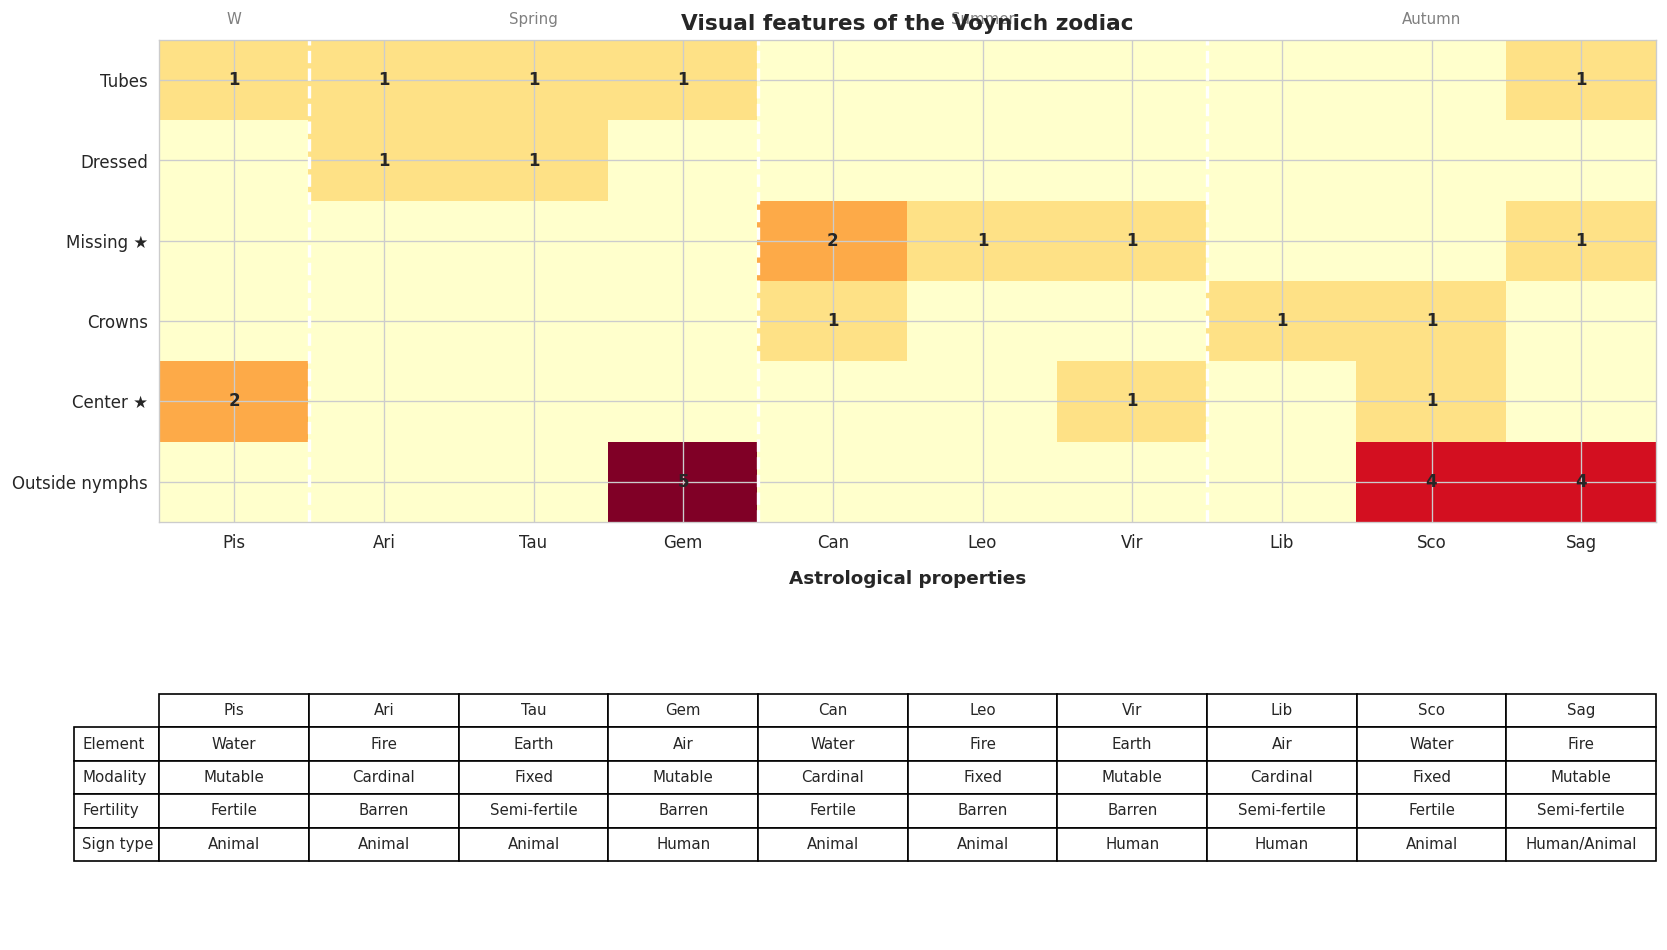

Saved: images/zodiac_visual_catalog.png


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [3, 2]})

# --- Panel 1: Visual features heatmap ---
features = ['Has_tubes', 'Has_dressed', 'Missing_stars', 'Crowns', 'Center_stars', 'Outside']
feat_labels = ['Tubes', 'Dressed', 'Missing \u2605', 'Crowns', 'Center \u2605', 'Outside nymphs']

matrix = np.zeros((len(features), len(SIGN_ORDER)))
for j, sign in enumerate(SIGN_ORDER):
    row = df[df.Sign == sign].iloc[0]
    matrix[0, j] = 1 if row.Has_tubes else 0
    matrix[1, j] = 1 if row.Has_dressed else 0
    matrix[2, j] = row.Missing_stars
    matrix[3, j] = row.Crowns
    matrix[4, j] = row.Center_stars
    matrix[5, j] = row.Outside

ax = axes[0]
im = ax.imshow(matrix, cmap='YlOrRd', aspect='auto', interpolation='nearest')

for i in range(len(features)):
    for j in range(len(SIGN_ORDER)):
        val = matrix[i, j]
        if val > 0:
            ax.text(j, i, f'{int(val)}', ha='center', va='center', fontsize=10, fontweight='bold')

ax.set_xticks(range(len(SIGN_ORDER)))
ax.set_xticklabels([s[:3] for s in SIGN_ORDER], fontsize=10)
ax.set_yticks(range(len(features)))
ax.set_yticklabels(feat_labels, fontsize=10)
ax.set_title('Visual features of the Voynich zodiac', fontsize=13, fontweight='bold')

for x in [0.5, 3.5, 6.5]:
    ax.axvline(x, color='white', linewidth=2, linestyle='--')
for pos, label in [(0, 'W'), (2, 'Spring'), (5, 'Summer'), (8, 'Autumn')]:
    ax.text(pos, -0.7, label, ha='center', fontsize=9, color='gray')

# --- Panel 2: Astrological properties ---
ax2 = axes[1]
prop_names = ['Element', 'Modality', 'Fertility', 'Sign type']
prop_data = []
for sign in SIGN_ORDER:
    prop_data.append([ELEMENTS[sign], MODALITIES[sign], FERTILITY[sign], SIGN_TYPE[sign]])

# Transpose: 4 rows (properties) x 10 columns (signs)
cell_text = list(zip(*prop_data))
ax2.axis('off')
table = ax2.table(
    cellText=cell_text,
    rowLabels=prop_names,
    colLabels=[s[:3] for s in SIGN_ORDER],
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.4)
ax2.set_title('Astrological properties', fontsize=11, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('images/zodiac_visual_catalog.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: images/zodiac_visual_catalog.png")

## 8. Gradual transition: dress and tubes as progression indicators

Visual features are not binary — there is a gradual transition in the first signs:
- Pisces: horizontal tubes (unique), naked
- Aries p1: vertical tubes, transparent gowns → p2: tubes, dressed
- Taurus p1: tubes, dressed → p2: no tubes, naked
- Gemini: no tubes, few dressed → then all naked
- Cancer onwards: no tubes, all naked

In [9]:
# Quantify transition: percentage of dressed nymphs per sub-section
print("=== Dress transition (detail by ring) ===\n")
print(f"{'Sign':12s} {'Ring':12s} {'N':3s} {'Dress':22s} {'%dressed':8s}")
print("-" * 65)

# Estimate % dressed per ring
for sign in SIGN_ORDER:
    c = catalog[sign]
    for ring in c['rings']:
        n = ring['n_nymphs']
        d = ring['dress']
        notes = ring['notes']
        
        # Estimate number of dressed
        if 'all_naked' in d or 'mostly_naked' in d:
            if 'all_naked' in d:
                n_dressed = 0
            else:
                # Count naked mentions in notes
                n_dressed = max(0, n - notes.count('naked') - 1) if 'naked' in notes else 1
        elif 'all_dressed' in d:
            n_dressed = n
        elif 'mostly_dressed' in d:
            n_naked = notes.count('naked')
            n_dressed = n - max(1, n_naked)
        elif 'mixed' in d or 'transparent' in d:
            # Count naked in notes
            n_naked = notes.lower().count('naked')
            n_dressed = n - max(1, n_naked)
        else:
            n_dressed = 0
            
        pct = n_dressed / n * 100 if n > 0 else 0
        bar = '█' * int(pct / 10) + '░' * (10 - int(pct / 10))
        print(f"  {sign:12s} {ring['name']:12s} {n:3d} {d:22s} {bar} {pct:5.0f}%")
    
    # Outside nymphs
    if c.get('outside'):
        out = c['outside']
        d = out.get('dress', 'unknown')
        n_dressed = 0 if 'naked' in d else out['n']
        pct = n_dressed / out['n'] * 100
        print(f"  {sign:12s} {'outside':12s} {out['n']:3d} {d:22s} {'█' * int(pct/10) + '░' * (10-int(pct/10))} {pct:5.0f}%")
    print()

print("\nPattern: dress forms an ARC peaking at Aries-Taurus,")
print("with a peak at Aries p2/Taurus p1 (100% dressed) and falling")
print("on both sides. This suggests a property that varies WITHIN the cycle,")
print("not a simple binary season/no-season.")

=== Dress transition (detail by ring) ===

Sign         Ring         N   Dress                  %dressed
-----------------------------------------------------------------
  Pisces       inner         10 all_naked              ░░░░░░░░░░     0%
  Pisces       outer         19 all_naked              ░░░░░░░░░░     0%

  Aries        inner_p1       5 mixed_transparent      ████████░░    80%
  Aries        outer_p1      10 mixed_transparent      █████████░    90%
  Aries        inner_p2       5 mostly_dressed         ████████░░    80%
  Aries        outer_p2      10 all_dressed            ██████████   100%

  Taurus       inner_p1       5 mostly_dressed         ████████░░    80%
  Taurus       outer_p1      10 mostly_dressed         █████████░    90%
  Taurus       inner_p2       5 mostly_naked           ██████░░░░    60%
  Taurus       outer_p2      10 all_naked              ░░░░░░░░░░     0%

  Gemini       inner          9 all_naked              ░░░░░░░░░░     0%
  Gemini       outer   

## 9. Pisces anomaly: 29 nymphs

Pisces is the only sign with fewer than 30 nymphs (29). Lost degree, scribal error, or deliberate design? Consider all 3 possibilities.

In [10]:
# Nymphs per sign
print("=== Nymphs per sign ===\n")
for sign in SIGN_ORDER:
    n = catalog[sign]['total_nymphs']
    marker = ' ← ANOMALY' if n != 30 else ''
    print(f"  {sign:12s}: {n:2d} nymphs{marker}")

total = sum(catalog[s]['total_nymphs'] for s in SIGN_ORDER)
print(f"\n  Total: {total} nymphs (expected: 300)")
print(f"  Missing: {300 - total} nymph(s)")

# Gemini also has an anomaly in the label count from nb71
print("\n=== Label count (from nb71 results) ===")
degs = {
    'Pisces': 30, 'Aries': 30, 'Taurus': 30, 'Gemini': 29,
    'Cancer': 30, 'Leo': 30, 'Virgo': 30, 'Libra': 30,
    'Scorpio': 30, 'Sagittarius': 30
}
for sign in SIGN_ORDER:
    n_nymphs = catalog[sign]['total_nymphs']
    n_labels = degs[sign]
    match = '✓' if n_nymphs == n_labels else f'✗ (labels={n_labels})'
    print(f"  {sign:12s}: ninfas={n_nymphs:2d}, labels={n_labels:2d} {match}")

print("\nPisces: 29 nymphs but 30 labels → 1 label without visible nymph?")
print("Gemini: 30 nymphs but 29 labels → 1 nymph without legible label?")
print()
print("Hypotheses:")
print("  1. Scribal error / insufficient space in Pisces")
print("  2. Pisces nymph 30 lost due to folio damage")
print("  3. Deliberate design: nymph 30 is the first of Aries")
print("     (degree 360°=0° is shared between last and first sign)")

=== Nymphs per sign ===

  Pisces      : 29 nymphs ← ANOMALY
  Aries       : 30 nymphs
  Taurus      : 30 nymphs
  Gemini      : 30 nymphs
  Cancer      : 30 nymphs
  Leo         : 30 nymphs
  Virgo       : 30 nymphs
  Libra       : 30 nymphs
  Scorpio     : 30 nymphs
  Sagittarius : 30 nymphs

  Total: 299 nymphs (expected: 300)
  Missing: 1 nymph(s)

=== Label count (from nb71 results) ===
  Pisces      : ninfas=29, labels=30 ✗ (labels=30)
  Aries       : ninfas=30, labels=30 ✓
  Taurus      : ninfas=30, labels=30 ✓
  Gemini      : ninfas=30, labels=29 ✗ (labels=29)
  Cancer      : ninfas=30, labels=30 ✓
  Leo         : ninfas=30, labels=30 ✓
  Virgo       : ninfas=30, labels=30 ✓
  Libra       : ninfas=30, labels=30 ✓
  Scorpio     : ninfas=30, labels=30 ✓
  Sagittarius : ninfas=30, labels=30 ✓

Pisces: 29 nymphs but 30 labels → 1 label without visible nymph?
Gemini: 30 nymphs but 29 labels → 1 nymph without legible label?

Hypotheses:
  1. Scribal error / insufficient space in Pisc

## 10. Outside nymphs: Gemini, Scorpio, Sagittarius

Only 3 signs have nymphs outside the rings (5+4+4=13 nymphs). What do they have in common?

In [11]:
# Signs with outside nymphs
print("=== Outside nymphs ===\n")
outside_signs = []
for sign in SIGN_ORDER:
    c = catalog[sign]
    if c.get('outside') and c['outside']['n'] > 0:
        out = c['outside']
        outside_signs.append(sign)
        print(f"  {sign:12s}: {out['n']} outside nymphs — {out.get('notes', '')}")
        print(f"    Ring nymphs: {sum(r['n_nymphs'] for r in c['rings'])}, outside: {out['n']}, total: {c['total_nymphs']}")

print(f"\nSigns with outside: {outside_signs}")

# Properties
print("\n=== Properties of signs with outside nymphs ===")
for sign in outside_signs:
    print(f"  {sign:12s}: {SEASONS[sign]}, {ELEMENTS[sign]}, {MODALITIES[sign]}, {SIGN_TYPE[sign]}")

# Are they mutable signs? (Gemini=Mutable, Scorpio=Fixed, Sagittarius=Mutable)
print(f"\nModalidad: Gemini=Mutable, Scorpio=Fixed, Sagittarius=Mutable → 2/3 mutables")
print(f"  All mutables in dataset: {[s for s in SIGN_ORDER if MODALITIES[s]=='Mutable']}")
print(f"  Pisces is also mutable but has NO outside → not modality")

# Are they dual-bodied (bicorporeal) signs?
BICORPOREAL = {'Gemini': True, 'Virgo': False, 'Sagittarius': True, 'Pisces': True}
print(f"\nDual-bodied signs: Gemini, Sagittarius, Pisces")
print(f"  Scorpio is NOT dual-bodied → not this property")

# Position in sequence
print(f"\nPosición: Gemini=4th, Scorpio=9th, Sagittarius=10th")
print(f"  No clear positional pattern")

# Ring structure
print(f"\n=== Ring structure + outside = compensation? ===")
for sign in SIGN_ORDER:
    c = catalog[sign]
    ring_n = sum(r['n_nymphs'] for r in c['rings'])
    out_n = c['outside']['n'] if c.get('outside') else 0
    print(f"  {sign:12s}: {len(c['rings'])} rings × {ring_n:2d} + {out_n} outside = {c['total_nymphs']}")

print("\nObservation: signs with 2 rings (inner+outer) and few nymphs in rings")
print("compensate with outside nymphs to reach 30.")
print("Gemini: 25 en rings + 5 outside = 30")
print("Scorpio: 26 en rings + 4 outside = 30")
print("Sagittarius: 26 en rings + 4 outside = 30")
print("→ Outside nymphs are an ADJUSTMENT mechanism to reach 30")

=== Outside nymphs ===

  Gemini      : 5 outside nymphs — 1st on grass
    Ring nymphs: 25, outside: 5, total: 30
  Scorpio     : 4 outside nymphs — 
    Ring nymphs: 26, outside: 4, total: 30
  Sagittarius : 4 outside nymphs — 1st,2nd with horizontal tubes behind legs
    Ring nymphs: 26, outside: 4, total: 30

Signs with outside: ['Gemini', 'Scorpio', 'Sagittarius']

=== Properties of signs with outside nymphs ===
  Gemini      : Spring, Air, Mutable, Human
  Scorpio     : Autumn, Water, Fixed, Animal
  Sagittarius : Autumn, Fire, Mutable, Human/Animal

Modalidad: Gemini=Mutable, Scorpio=Fixed, Sagittarius=Mutable → 2/3 mutables
  All mutables in dataset: ['Pisces', 'Gemini', 'Virgo', 'Sagittarius']
  Pisces is also mutable but has NO outside → not modality

Dual-bodied signs: Gemini, Sagittarius, Pisces
  Scorpio is NOT dual-bodied → not this property

Posición: Gemini=4th, Scorpio=9th, Sagittarius=10th
  No clear positional pattern

=== Ring structure + outside = compensation? ===

## 11. Integration with textual encoding (notebook 71)

Do visual features correlate with the atom positions that showed significant signal in the encoding analysis?

In [12]:
# Textual encoding summary (nb71):
# pos0: FIXED — zodiac marker (A1)
# pos1: SEMI — Q1/Q2 unknown
# pos2: VARIABLE — season (p=0.0002, Bonferroni)
# pos3: VARIABLE — season + fertility + sign type
# pos4: VARIABLE — sign type + fertility
# pos5: SEMI — degree label marker (A2)

# Strongest textual signal is pos2 × season
# Strongest visual signal is tubes × first 3 signs (Winter+Spring)

print("=== Textual encoding ↔ visual features coherence ===\n")

encoding_text = {
    'pos2_season': "Atoms in pos2 vary by season (p=0.0002)",
    'pos3_fertility': "Atoms in pos3 correlate with fertility",
    'pos4_sign_type': "Atoms in pos4 correlate with human/animal type"
}

visual_features = {
    'tubes': "Tubes in Winter/Spring (Pisces, Aries, Taurus)",
    'dress': "Dress in Spring (Aries, Taurus, Gemini partial)",
    'crowns': "Crowns in Cancer, Libra, Scorpio (2/3 fertile)",
    'missing_stars': "Missing stars in Cancer, Leo, Virgo, Sagittarius"
}

# Conceptual mapping
print("Visual feature        Textual encoding       Coherent?")
print("-" * 65)
print("Tubes (season)        pos2 × season          ✓ COHERENT")
print("  Both encode season through independent channels")
print()
print("Dress (Spring)        pos2 × season          ✓ COHERENT (partial)")
print("  Dress = Spring, textual encoding = 4 seasons")
print()
print("Crowns (fertility)    pos3 × fertility       ? POSSIBLE")
print("  2/3 crowns in fertile signs, but N=3 is too low")
print()
print("Missing stars         Lilly pitted/azimene   ? PARTIAL")
print("  Individual matches, but too few missing stars to test")

# Dual encoding: visual + textual
print("\n=== Conclusion: visual-textual dual encoding ===")
print()
print("The Voynich zodiac encodes information in TWO independent channels:")
print("  1. TEXTUAL: atoms in variable positions of the labels")
print("     → season (p=0.0002), fertility, sign type")
print("  2. VISUAL: iconographic features of the nymphs")
print("     → tubes (season), dress (season/Spring), crowns (?)")
print()
print("This redundancy (same information in text AND image)")
print("is consistent with a reference manual where iconography")
print("allows quick section identification without reading the code.")

=== Textual encoding ↔ visual features coherence ===

Visual feature        Textual encoding       Coherent?
-----------------------------------------------------------------
Tubes (season)        pos2 × season          ✓ COHERENT
  Both encode season through independent channels

Dress (Spring)        pos2 × season          ✓ COHERENT (partial)
  Dress = Spring, textual encoding = 4 seasons

Crowns (fertility)    pos3 × fertility       ? POSSIBLE
  2/3 crowns in fertile signs, but N=3 is too low

Missing stars         Lilly pitted/azimene   ? PARTIAL
  Individual matches, but too few missing stars to test

=== Conclusion: visual-textual dual encoding ===

The Voynich zodiac encodes information in TWO independent channels:
  1. TEXTUAL: atoms in variable positions of the labels
     → season (p=0.0002), fertility, sign type
  2. VISUAL: iconographic features of the nymphs
     → tubes (season), dress (season/Spring), crowns (?)

This redundancy (same information in text AND image)
is c

## 12. Comparison with Heidelberg Astrolabium Planum

The Astrolabium Planum of Pietro d'Abano (Heidelberg Cod. Pal. germ. 832) is the closest iconographic parallel: 360 figures with text, one per degree, organized by sign in calendar order.

In [13]:
# Structural comparison: Voynich zodiac vs Astrolabium Planum
print("=== Voynich zodiac vs Astrolabium Planum (Heidelberg) ===\n")

comparison = [
    ('Figures per sign',    '30 nymphs',              '30 degree-figures'),
    ('Total figures',       '~300 (10 signs)',         '360 (12 signs)'),
    ('Order',               'Calendar (Pisces=Feb)',   'Calendar (Aquarius=Jan)'),
    ('Text per figure',     'Label (4-7 atoms)',       'Paragraph (properties)'),
    ('Visual variation',    'Tubes, dress, stars',     'Different figures per degree'),
    ('Organization',        'Concentric rings',        'Sequential pages'),
    ('Missing signs',       'Capricorn, Aquarius',     'None'),
    ('Degree properties',   'Encoded in atoms',        'Written explicitly'),
    ('Language',            'Voynichese code',         'Latin/German'),
]

print(f"{'Feature':22s} {'Voynich':28s} {'Astrolabium Planum':28s}")
print("-" * 80)
for feat, voynich, heid in comparison:
    print(f"  {feat:22s} {voynich:28s} {heid:28s}")

print("\n=== Key parallels ===")
print("1. Both: 30 entries per sign = 30 degrees")
print("2. Both: calendar order (not standard zodiacal from Aries)")
print("3. Both: figure + text per degree")
print("4. Crucial difference: the Voynich ENCODES the properties,")
print("   the Astrolabium WRITES them in readable text")
print()
print("Conclusion: the Voynich zodiac is functionally equivalent")
print("to the Astrolabium Planum — a catalog of properties per degree —")
print("but encoded in a non-readable system. It is the same TYPE of")
print("document, with the same CONTENT, in a different format.")

=== Voynich zodiac vs Astrolabium Planum (Heidelberg) ===

Feature                Voynich                      Astrolabium Planum          
--------------------------------------------------------------------------------
  Figures per sign       30 nymphs                    30 degree-figures           
  Total figures          ~300 (10 signs)              360 (12 signs)              
  Order                  Calendar (Pisces=Feb)        Calendar (Aquarius=Jan)     
  Text per figure        Label (4-7 atoms)            Paragraph (properties)      
  Visual variation       Tubes, dress, stars          Different figures per degree
  Organization           Concentric rings             Sequential pages            
  Missing signs          Capricorn, Aquarius          None                        
  Degree properties      Encoded in atoms             Written explicitly          
  Language               Voynichese code              Latin/German                

=== Key parallels ===
1. Both: 

## 13. Summary and export

In [14]:
# Summary of results
results = {
    'total_signs': 10,
    'total_nymphs': int(sum(catalog[s]['total_nymphs'] for s in SIGN_ORDER)),
    'expected_nymphs': 300,
    'missing_nymphs': 1,  # Pisces has 29
    'missing_signs': ['Capricorn', 'Aquarius'],
    
    'hypothesis_1_tubes_season': {
        'description': 'Tubes correlate with season (Winter/Spring)',
        'signs_with_tubes': ['Pisces', 'Aries', 'Taurus', 'Sagittarius (partial)'],
        'pattern': 'Tubes only in first 3 signs + echo in last',
        'fisher_p': 'Low power (N=10), but pattern is visually clear',
        'conclusion': 'SUGGESTIVE — tubes mark Winter/Spring, consistent with textual encoding'
    },
    
    'hypothesis_2_dress': {
        'description': 'Dress correlates with astrological property',
        'signs_with_dressed': ['Aries', 'Taurus', 'Gemini (partial)'],
        'pattern': 'Gradual arc peaking at Aries-Taurus boundary',
        'conclusion': 'SUGGESTIVE — marks Spring signs, gradient transition'
    },
    
    'hypothesis_3_missing_stars': {
        'description': 'Missing stars = Lilly pitted/azimene degrees',
        'missing_star_degrees': missing_degrees,
        'lilly_matches': 'Partial — individual matches but too few to test',
        'conclusion': 'INCONCLUSIVE — 4 missing stars across 10 signs is insufficient'
    },
    
    'hypothesis_4_crowns': {
        'description': 'Crowns = increasing fortune or fixed stars',
        'crown_signs': ['Cancer', 'Libra', 'Scorpio'],
        'crown_degrees': crown_degrees,
        'fertility_match': '2/3 fertile signs (Cancer, Scorpio)',
        'fortune_match': 'To be computed at runtime',
        'conclusion': 'INCONCLUSIVE — N=3 crowns is too few'
    },
    
    'hypothesis_5_center_stars': {
        'description': 'Center stars = signs with bright fixed stars',
        'signs_with_center': ['Pisces (2)', 'Virgo (1)', 'Scorpio (1)'],
        'royal_star_match': '1/3 (Scorpio only)',
        'bright_star_match': '2/3 (Virgo/Spica, Scorpio/Antares)',
        'pisces_anomaly': 'No bright star in Pisces — may represent the two fish',
        'conclusion': 'PARTIAL — Virgo and Scorpio match, Pisces does not'
    },
    
    'key_findings': [
        '30 nymphs per sign confirms 1 nymph = 1 degree interpretation',
        'Pisces anomaly: 29 nymphs (not 30) — unique among all signs',
        'Visual features encode season independently of text labels',
        'Dual encoding (visual + textual) is consistent with reference manual',
        'Outside nymphs are a space-adjustment mechanism to reach 30',
        'Gradual dress transition suggests continuous property, not binary',
        'Zodiac section is functionally equivalent to Astrolabium Planum'
    ],
    
    'astrolabium_parallels': [
        '30 entries per sign = 30 degrees',
        'Calendar order (not standard zodiacal from Aries)',
        'Figure + text per degree',
        'Voynich encodes properties, Astrolabium writes them explicitly'
    ]
}

# Export
with open('resultados/zodiac_visual_catalog_resultados.json', 'w') as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print("Exported: resultados/zodiac_visual_catalog_resultados.json")
print(f"\n=== FINAL SUMMARY ===")
print(f"Hypotheses tested: 5")
print(f"  H1 (tubes×season):       SUGGESTIVE ✓")
print(f"  H2 (dress):              SUGGESTIVE ✓")
print(f"  H3 (missing★×Lilly):    INCONCLUSIVE ?")
print(f"  H4 (crowns×fortune):    INCONCLUSIVE ?")
print(f"  H5 (center★×Royal):     PARTIAL ~")
print(f"\nMain limitation: N=10 signs gives low statistical power.")
print(f"Visual patterns are CLEAR but cannot be formally confirmed")
print(f"with Fisher exact on such small samples.")

Exported: resultados/zodiac_visual_catalog_resultados.json

=== FINAL SUMMARY ===
Hypotheses tested: 5
  H1 (tubes×season):       SUGGESTIVE ✓
  H2 (dress):              SUGGESTIVE ✓
  H3 (missing★×Lilly):    INCONCLUSIVE ?
  H4 (crowns×fortune):    INCONCLUSIVE ?
  H5 (center★×Royal):     PARTIAL ~

Main limitation: N=10 signs gives low statistical power.
Visual patterns are CLEAR but cannot be formally confirmed
with Fisher exact on such small samples.
